# **Tugas Praktikum 1: Scraping & Eksplorasi Data (EDA)**


### Sandi Suryo Nugroho

### 5054251020

 Website yang akan di scrapping adalah RAWG, salah satu database video game dan layanan penemuan (game discovery) terbesar di dunia. Platform RAWG.io ini sering disebut sebagai "IMDb-nya dunia game", untuk mencari informasi dan data mengenai game-game.


## **1. Scrapping Dataset (https://api.rawg.io/api/games) menjadi CSV**

In [36]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import time
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
API_KEY = "c00757c2333846849dd7646ffb5843f8"
BASE_URL = "https://api.rawg.io/api/games"

def extract_names(items):
    if not items:
        return None
    return ", ".join(item["name"] for item in items)

# Scraping data
all_games = []

for page in range(1, 51):  # 50 halaman × 40 data = 2.000 game
    print(f"Scraping halaman {page}/50...")

    params = {
        "key": API_KEY,
        "page": page,
        "page_size": 40
    }

    response = requests.get(BASE_URL, params=params)

    if response.status_code != 200:
        print(f"Error pada halaman {page}: {response.status_code}")
        continue

    data = response.json()

    for game in data["results"]:
        all_games.append({
            "id": game["id"],
            "name": game["name"],
            "released": game["released"],
            "rating": game["rating"],
            "ratings_count": game["ratings_count"],
            "metacritic": game["metacritic"],
            "playtime": game["playtime"],
            "genres": extract_names(game["genres"]),
            "platforms": extract_names(
                [p["platform"] for p in game["platforms"]]
            ),
            "esrb_rating": (
                game["esrb_rating"]["name"]
                if game["esrb_rating"]
                else None
            )
        })

    time.sleep(0.5)

df = pd.DataFrame(all_games)

# Simpan hasil scraping ke CSV
df.to_csv("rawg_games_raw.csv", index=False)

print("\nScraping selesai!")
print(f"Total data: {len(df)}")
print(f"Total kolom: {len(df.columns)}")
print("File tersimpan sebagai: rawg_games_raw.csv")


df.head()

Scraping halaman 1/50...
Scraping halaman 2/50...
Scraping halaman 3/50...
Scraping halaman 4/50...
Scraping halaman 5/50...
Scraping halaman 6/50...
Scraping halaman 7/50...
Scraping halaman 8/50...
Scraping halaman 9/50...
Scraping halaman 10/50...
Scraping halaman 11/50...
Scraping halaman 12/50...
Scraping halaman 13/50...
Scraping halaman 14/50...
Scraping halaman 15/50...
Scraping halaman 16/50...
Scraping halaman 17/50...
Scraping halaman 18/50...
Scraping halaman 19/50...
Scraping halaman 20/50...
Scraping halaman 21/50...
Scraping halaman 22/50...
Scraping halaman 23/50...
Scraping halaman 24/50...
Scraping halaman 25/50...
Scraping halaman 26/50...
Scraping halaman 27/50...
Scraping halaman 28/50...
Scraping halaman 29/50...
Scraping halaman 30/50...
Scraping halaman 31/50...
Scraping halaman 32/50...
Scraping halaman 33/50...
Scraping halaman 34/50...
Scraping halaman 35/50...
Scraping halaman 36/50...
Scraping halaman 37/50...
Scraping halaman 38/50...
Scraping halaman 39/5

,id,name,released,rating,ratings_count,metacritic,playtime,genres,platforms,esrb_rating
0,3498,Grand Theft Auto V,2013-09-17,4.47,7440,92.0,74,Action,"PlayStation 5, Xbox Series S/X, PlayStation 3,...",Mature
1,3328,The Witcher 3: Wild Hunt,2015-05-18,4.64,7277,92.0,43,"Action, RPG","PlayStation 5, Xbox Series S/X, macOS, PlaySta...",Mature
2,4200,Portal 2,2011-04-18,4.57,6139,95.0,11,"Shooter, Puzzle","PlayStation 3, PC, Xbox 360, Linux, macOS, Xbo...",Everyone 10+
3,4291,Counter-Strike: Global Offensive,2012-08-21,3.57,3644,81.0,64,Shooter,"PC, Linux, Xbox 360, PlayStation 3",Mature
4,13536,Portal,2007-10-09,4.49,5054,90.0,4,"Action, Puzzle","macOS, PC, Android, PlayStation 3, Xbox 360, L...",Teen


## **2. Struktur Dataset**

In [26]:
df = pd.read_csv("rawg_games_raw.csv")

print("Shape:", df.shape)
df.info()
df.head()

Shape: (2000, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             2000 non-null   int64  
 1   name           2000 non-null   object 
 2   released       1996 non-null   object 
 3   rating         2000 non-null   float64
 4   ratings_count  2000 non-null   int64  
 5   metacritic     1570 non-null   float64
 6   playtime       2000 non-null   int64  
 7   genres         1994 non-null   object 
 8   platforms      2000 non-null   object 
 9   esrb_rating    1340 non-null   object 
dtypes: float64(2), int64(3), object(5)
memory usage: 156.4+ KB


,id,name,released,rating,ratings_count,metacritic,playtime,genres,platforms,esrb_rating
0,3498,Grand Theft Auto V,2013-09-17,4.47,7440,92.0,74,Action,"PlayStation 5, Xbox Series S/X, PlayStation 3,...",Mature
1,3328,The Witcher 3: Wild Hunt,2015-05-18,4.64,7277,92.0,43,"Action, RPG","PlayStation 5, Xbox Series S/X, macOS, PlaySta...",Mature
2,4200,Portal 2,2011-04-18,4.57,6139,95.0,11,"Shooter, Puzzle","PlayStation 3, PC, Xbox 360, Linux, macOS, Xbo...",Everyone 10+
3,4291,Counter-Strike: Global Offensive,2012-08-21,3.57,3644,81.0,64,Shooter,"PC, Linux, Xbox 360, PlayStation 3",Mature
4,13536,Portal,2007-10-09,4.49,5054,90.0,4,"Action, Puzzle","macOS, PC, Android, PlayStation 3, Xbox 360, L...",Teen


| Atribut         | Tipe                   | Penjelasan                                                                                                              |
| --------------- | ---------------------- | ----------------------------------------------------------------------------------------------------------------------- |
| `id`            | **Numerik (diskrit)***| Berupa bilangan bulat, tetapi sebenarnya berfungsi sebagai **identifier**, bukan nilai yang dianalisis secara statistik |
| `name`          | **Nominal**            | Nama game, hanya sebagai kategori/label                                                                                 |
| `released`      | **Numerik (kontinu)** | Tanggal rilis dapat dikonversi menjadi nilai waktu/tanggal untuk analisis                                               |
| `rating`        | **Numerik (kontinu)**  | Nilai rating, misalnya 4.25, 3.80                                                                                       |
| `ratings_count` | **Numerik (diskrit)**  | Jumlah orang yang memberikan rating, berupa bilangan bulat                                                              |
| `metacritic`    | **Numerik (diskrit)**  | Skor Metacritic berupa bilangan bulat, umumnya 0–100                                                                    |
| `playtime`      | **Numerik (diskrit)**  | Estimasi waktu bermain dalam jam, berupa bilangan bulat                                                                 |
| `genres`        | **Nominal**            | Kategori genre game seperti Action, RPG, Strategy                                                                       |
| `platforms`     | **Nominal**            | Kategori platform seperti PC, PlayStation, Xbox                                                                         |
| `esrb_rating`   | **Ordinal**            | Rating usia seperti Everyone, Teen, Mature yang memiliki tingkatan usia                                                 |


## **3. Analisis Statistik dan Kualitas Data**

### 3.1 Statistik deskriptif atribut numerik

In [27]:
numeric_cols = ["rating", "ratings_count", "metacritic", "playtime"]

mean = df[numeric_cols].mean()
median = df[numeric_cols].median()
mode = df[numeric_cols].mode().iloc[0]
std = df[numeric_cols].std()
minimum = df[numeric_cols].min()
maximum = df[numeric_cols].max()

statistik = pd.DataFrame({
    "Mean": mean,
    "Median": median,
    "Modus": mode,
    "Standar Deviasi": std,
    "Minimum": minimum,
    "Maksimum": maximum
})

statistik

,Mean,Median,Modus,Standar Deviasi,Minimum,Maksimum
rating,3.569140,3.68,4.38,0.617340,1.5,4.8
ratings_count,587.226000,333.00,132.00,709.468341,11.0,7440.0
metacritic,78.388535,79.00,80.00,8.605770,39.0,99.0
playtime,5.234000,3.00,1.00,10.161834,0.0,329.0


### 3.2 Frekuensi atribut kategorikal

In [28]:
# Genre
genres = (
    df["genres"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
)

print("=== FREKUENSI GENRE ===")
print(genres)

# Platform
platforms = (
    df["platforms"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
)

print("\n=== FREKUENSI PLATFORM ===")
print(platforms)

# Rating
print("\n=== FREKUENSI ESRB RATING ===")
print(df["esrb_rating"].value_counts(dropna=False))

=== FREKUENSI GENRE ===
genres
Action                   1316
Adventure                 774
Indie                     717
RPG                       483
Shooter                   362
Strategy                  361
Simulation                235
Casual                    197
Platformer                146
Puzzle                    142
Arcade                    128
Racing                     94
Massively Multiplayer      81
Sports                     71
Family                     41
Fighting                   33
Card                       14
Board Games                13
Educational                11
Name: count, dtype: int64

=== FREKUENSI PLATFORM ===
platforms
PC                    1909
PlayStation 4          947
Xbox One               936
macOS                  819
Linux                  563
Nintendo Switch        554
Xbox 360               440
PlayStation 3          435
iOS                    360
Android                255
PlayStation 5          154
Xbox Series S/X        142
PS Vita    

### 3.3 Missing Value

In [29]:
missing = pd.DataFrame({
    "Jumlah Missing": df.isnull().sum(),
    "Persentase Missing (%)": 
        (df.isnull().sum() / len(df) * 100).round(2)
})

missing = missing.sort_values(
    by="Jumlah Missing",
    ascending=False
)

missing

,Jumlah Missing,Persentase Missing (%)
esrb_rating,660,33.0
metacritic,430,21.5
genres,6,0.3
released,4,0.2
name,0,0.0
id,0,0.0
ratings_count,0,0.0
rating,0,0.0
playtime,0,0.0
platforms,0,0.0


### 3.4 Deteksi Outlier

In [30]:
numeric_cols = ["rating", "ratings_count", "metacritic", "playtime"]

outlier_summary = []

for col in numeric_cols:
    # Hilangkan missing value sementara
    data = df[col].dropna()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data < lower_bound) | 
        (data > upper_bound)
    ]

    outlier_summary.append({
        "Atribut": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Batas Bawah": lower_bound,
        "Batas Atas": upper_bound,
        "Jumlah Outlier": len(outliers),
        "Persentase Outlier (%)": round(
            len(outliers) / len(data) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary

,Atribut,Q1,Q3,IQR,Batas Bawah,Batas Atas,Jumlah Outlier,Persentase Outlier (%)
0,rating,3.2,4.04,0.84,1.940,5.300,24,1.20
1,ratings_count,171.0,705.25,534.25,-630.375,1506.625,182,9.10
2,metacritic,73.0,84.00,11.00,56.500,100.500,21,1.34
3,playtime,2.0,5.00,3.00,-2.500,9.500,240,12.00


### 3.5 Game yang menjadi Outlier

In [ ]:
data = df["playtime"].dropna()

Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

playtime_outliers = df[
    (df["playtime"] < lower_bound) |
    (df["playtime"] > upper_bound)
]

playtime_outliers[
    ["name", "playtime", "rating", "genres"]
].sort_values(
    "playtime",
    ascending=False
).head(10)

,name,playtime,rating,genres
1030,Vampire: The Masquerade – Bloodlines 2,329,3.83,"Action, RPG"
255,The Legend of Zelda: Breath of the Wild,121,4.47,"Action, Adventure, RPG"
430,Persona 5,105,4.34,"Action, Adventure, RPG"
1131,Halo 4,75,3.83,"Action, Shooter"
0,Grand Theft Auto V,74,4.47,Action
3,Counter-Strike: Global Offensive,64,3.57,Shooter
146,Elden Ring,62,4.38,"Action, RPG"
1090,Diablo III,58,4.09,"Action, RPG"
696,Dark Souls,48,4.34,"Action, RPG"
1733,Ni no Kuni: Wrath of the White Witch,47,4.18,RPG


## **4. Visualisasi Data**

### 4.1 Distribusi Rating (Histogram)

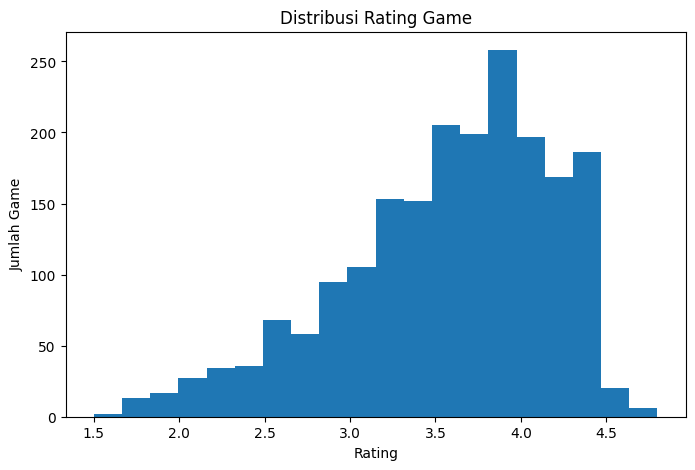

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    df["rating"].dropna(),
    bins=20
)

plt.xlabel("Rating")
plt.ylabel("Jumlah Game")
plt.title("Distribusi Rating Game")

plt.show()

Berdasarkan histogram, distribusi rating game menunjukkan bahwa sebagian besar game berada pada rentang rating tertentu. Hal ini menunjukkan bahwa game dengan rating pada rentang tersebut merupakan bagian terbesar dari dataset. Distribusi juga dapat digunakan untuk melihat apakah rating cenderung terpusat atau tersebar.

### 4.2 Genre Terbanyak (Bar Chart)

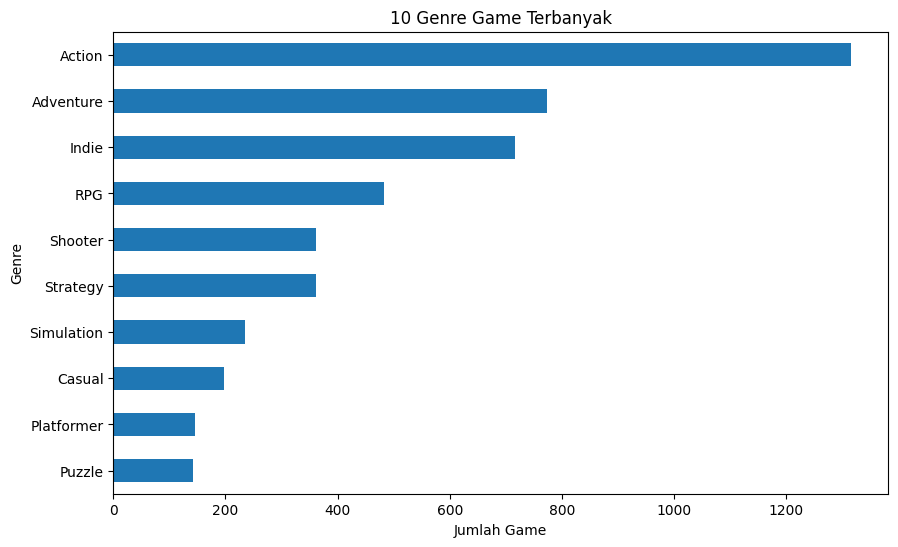

In [33]:
genre_counts = (
    df["genres"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))

genre_counts.sort_values().plot(
    kind="barh"
)

plt.xlabel("Jumlah Game")
plt.ylabel("Genre")
plt.title("10 Genre Game Terbanyak")

plt.show()

Berdasarkan bar chart, terlihat bahwa beberapa genre memiliki jumlah game yang jauh lebih banyak dibandingkan genre lainnya. Genre game _Action_ menunjukkan bahwa genre tersebut paling banyak ditemukan dalam dataset RAWG yang digunakan.

### 4.3 Metacritic vs RAWG Rating 

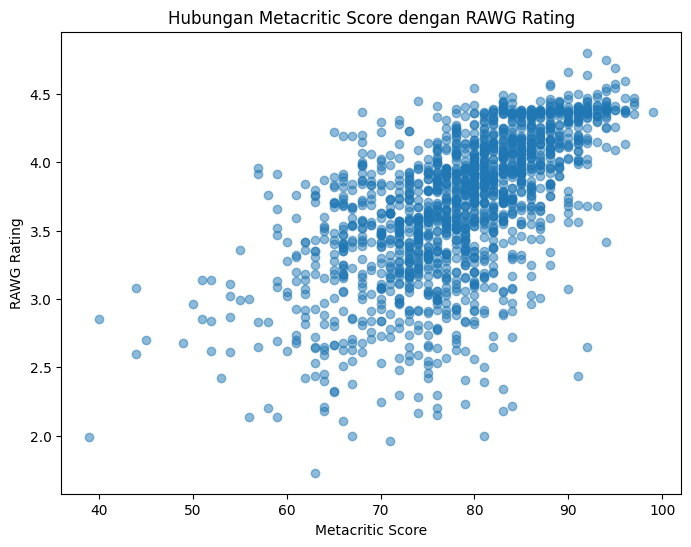

In [34]:
plt.figure(figsize=(8, 6))

scatter_data = df[
    ["metacritic", "rating"]
].dropna()

plt.scatter(
    scatter_data["metacritic"],
    scatter_data["rating"],
    alpha=0.5
)

plt.xlabel("Metacritic Score")
plt.ylabel("RAWG Rating")
plt.title("Hubungan Metacritic Score dengan RAWG Rating")

plt.show()

Berdasarkan scatter plot, terdapat hubungan positif antara Metacritic Score dan RAWG Rating. Terlihat bahwa semakin tinggi skor Metacritic, rating RAWG cenderung semakin tinggi. Namun, titik data masih cukup tersebar sehingga hubungan tersebut tidak sepenuhnya kuat. Hal ini menunjukkan bahwa skor Metacritic memiliki kecenderungan searah dengan rating RAWG, tetapi bukan satu-satunya faktor yang menentukan rating sebuah game.

### 4.4 Rating Berdasarkan Genre (Boxplot)

<Figure size 1000x600 with 0 Axes>

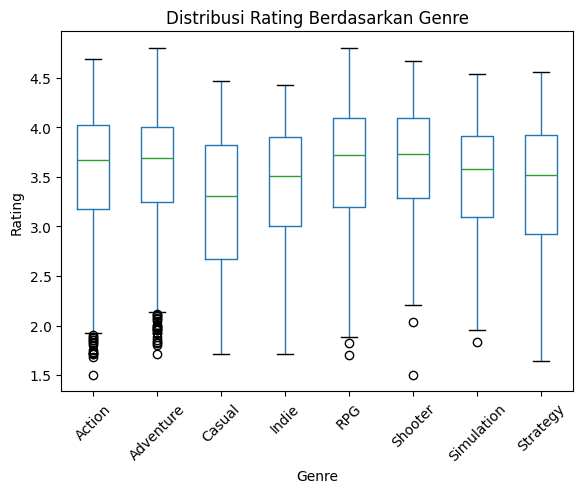

In [35]:
genre_data = df[
    ["genres", "rating"]
].dropna()

genre_data = genre_data.assign(
    genres=genre_data["genres"].str.split(", ")
).explode("genres")

top_genres = (
    genre_data["genres"]
    .value_counts()
    .head(8)
    .index
)

genre_boxplot = genre_data[
    genre_data["genres"].isin(top_genres)
]

plt.figure(figsize=(10, 6))

genre_boxplot.boxplot(
    column="rating",
    by="genres",
    grid=False
)

plt.xlabel("Genre")
plt.ylabel("Rating")
plt.title("Distribusi Rating Berdasarkan Genre")
plt.suptitle("")

plt.xticks(rotation=45)

plt.show()

Genre **RPG, Shooter, Adventure, dan Action** memiliki median rating paling tinggi (sekitar 3,7), menunjukkan kepuasan pengguna yang umumnya tinggi pada genre ini. 

Genre **Casual dan Strategy** memiliki rentang kotak yang paling lebar, menandakan variasi kualitas atau persepsi pemain yang lebih beragam. 

Genre **Action dan Adventure** memiliki banyak outlier di batas bawah (rating 1,5–2,2). Hal ini wajar karena jumlah game pada kedua genre tersebut sangat banyak, sehingga peluang adanya game berkualitas buruk bertambah. 

Genre **Indie dan RPG** cenderung memiliki batas bawah nilai yang relatif lebih stabil dibanding Action/Adventure. 


### 4.5 Correlation Heatmap

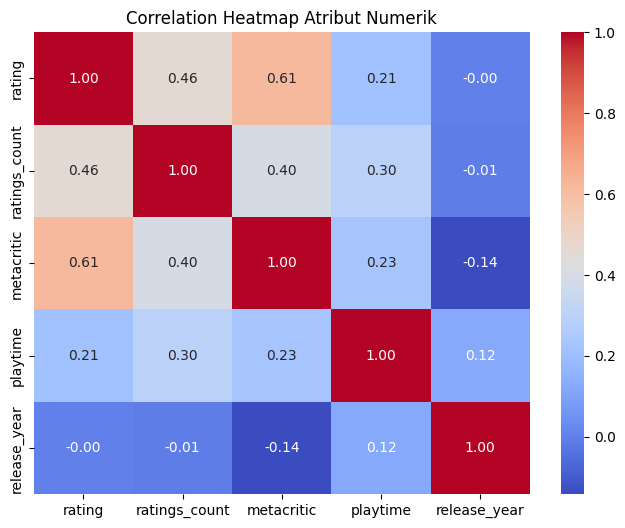

In [37]:
df["released"] = pd.to_datetime(
    df["released"],
    errors="coerce"
)

df["release_year"] = df["released"].dt.year

numeric_cols = [
    "rating",
    "ratings_count",
    "metacritic",
    "playtime",
    "release_year"
]

correlation = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap Atribut Numerik")

plt.show()

Korelasi **Terkuat** (rating vs metacritic = 0,61): Memiliki korelasi positif sedang hingga kuat. Kualitas yang dinilai baik oleh kritikus profesional sejalan dengan penilaian pengguna RAWG. 

Korelasi **Cukup Kuat** (rating vs ratings_count = 0,46): Game yang memiliki nilai rating tinggi cenderung memikat lebih banyak pemain untuk memberikan ulasan. 

Korelasi **Popularitas & Kritikus** (metacritic vs ratings_count = 0,40): Game dengan skor Metacritic tinggi umumnya mendapatkan popularitas dan jumlah ulasan pemain yang lebih banyak. 

Korelasi **Lemah** (playtime): playtime hanya memiliki korelasi lemah dengan metacritic (0,23), rating (0,21), dan ratings_count (0,30). Durasi game yang lama tidak menjamin skor ulasan lebih tinggi. 

**Tidak Ada Korelasi** (release_year): Tahun rilis tidak memengaruhi rating (-0,00) maupun ratings_count (-0,01). Game lama dan baru memiliki peluang yang sama untuk disukai atau populer. 
